In [1]:
import os, sys, json, hashlib
os.chdir('..'); sys.path.insert(0, 'src')
import numpy as np, soundfile as sf, matplotlib.pyplot as plt
from collections import Counter
import gmm_vc
from mcd import mcd

## 1. Проверка данных
Формат, NaN/Inf, дубликаты по SHA256 файлов, утечка между выборками.

In [2]:
res = {}
for spk in ('bdl', 'slt'):
    files = sorted(f'data/raw/cmu_us_{spk}_arctic/wav/{n}' for n in os.listdir(f'data/raw/cmu_us_{spk}_arctic/wav'))
    hashes, bad = [], 0
    for f in files:
        x, fs = sf.read(f)
        bad += int(fs != 16000 or x.ndim != 1 or not np.all(np.isfinite(x)))
        hashes.append(hashlib.sha256(open(f, 'rb').read()).hexdigest())
    res[spk] = {'files': len(files), 'bad': bad, 'duplicate_files': len(hashes) - len(set(hashes))}
print(res)
s = json.load(open('data/splits.json'))
print({k: len(s[k]) for k in ('train', 'val', 'test')})
print('пересечения:', len(set(s['train']) & set(s['test'])), len(set(s['train']) & set(s['val'])), len(set(s['val']) & set(s['test'])))

{'bdl': {'files': 1132, 'bad': 0, 'duplicate_files': 0}, 'slt': {'files': 1132, 'bad': 0, 'duplicate_files': 0}}
{'train': 906, 'val': 113, 'test': 113}
пересечения: 0 0 0


## 2. Метрики на тесте (MCD, дБ, меньше - лучше)

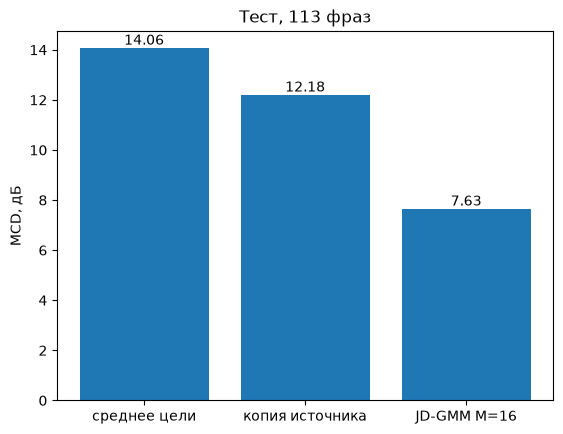

In [3]:
m = json.load(open('metrics/baseline.json'))
names = ['среднее цели', 'копия источника', 'JD-GMM M=16']
vals = [m['value_mean_target'], m['value_copy_source'], m['value_gmm']]
plt.bar(names, vals); plt.ylabel('MCD, дБ')
for i, v in enumerate(vals): plt.text(i, v + 0.15, f'{v:.2f}', ha='center')
plt.title('Тест, 113 фраз'); os.makedirs('docs', exist_ok=True)
plt.savefig('docs/mcd_test.png', dpi=120, bbox_inches='tight'); plt.show()

## 3. Ошибки по фразам

лучшие: [(6.582843306222316, 'arctic_a0287', 276), (6.6709350105080585, 'arctic_a0005', 323), (6.987654526924269, 'arctic_a0122', 669)]
худшие: [(8.276154915608146, 'arctic_b0310', 699), (8.289223609790067, 'arctic_b0032', 386), (8.366406997029433, 'arctic_b0045', 454), (8.627225150349314, 'arctic_a0508', 809), (8.718950751556942, 'arctic_b0023', 542)]


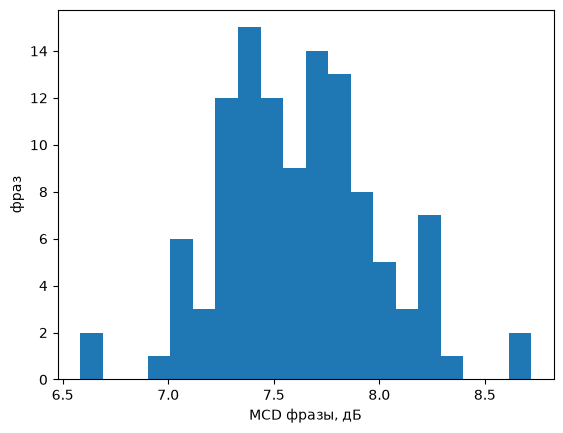

In [4]:
te = np.load('data/aligned/test.npz', allow_pickle=False)
model = gmm_vc.load('models/gmm_M16.npz')
Yh = gmm_vc.convert(model, te['X'])
per = []
for k, name in enumerate(te['ids']):
    idx = te['utt'] == k
    per.append((float(mcd(Yh[idx], te['Y'][idx])), str(name), int(idx.sum())))
per.sort()
print('лучшие:', per[:3])
print('худшие:', per[-5:])
plt.hist([p[0] for p in per], bins=20); plt.xlabel('MCD фразы, дБ'); plt.ylabel('фраз')
plt.savefig('docs/mcd_per_phrase.png', dpi=120, bbox_inches='tight'); plt.show()